# DSH Jupyter 集成 · 冒烟演示

这个 notebook 由 DSH 的 `mcp__jupyter__*` 工具创建：cell 的插入与执行都走 MCP，输出直接写回 `.ipynb`，图片既回到聊天里，也落盘成 PNG。

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
months = ["1月", "2月", "3月", "4月", "5月", "6月"]
sales = pd.DataFrame({
    "月份": months,
    "销售额": rng.integers(120, 320, len(months)),
    "订单数": rng.integers(40, 120, len(months)),
})
sales["客单价"] = (sales["销售额"] / sales["订单数"]).round(1)
sales

,月份,销售额,订单数,客单价
0,1月,137,46,3.0
1,2月,274,95,2.9
2,3月,250,56,4.5
3,4月,207,47,4.4
4,5月,206,82,2.5
5,6月,291,118,2.5


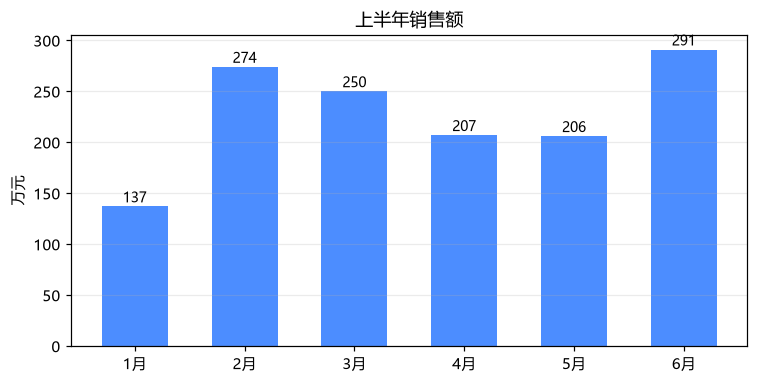

In [3]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
ax.bar(sales["月份"], sales["销售额"], color="#4c8dff", width=0.6)
ax.set_title("上半年销售额")
ax.set_ylabel("万元")
ax.grid(axis="y", alpha=0.25)
for x, y in zip(sales["月份"], sales["销售额"]):
    ax.text(x, y + 4, str(y), ha="center", fontsize=9)
fig.tight_layout()

## 状态检查

下面的 cell 验证内核状态在 cell 之间是保留的：`sales` 还在，中文与相对路径也正常。

In [4]:
from pathlib import Path

print("总销售额:", int(sales["销售额"].sum()), "万元")
print("最佳月份:", sales.loc[sales["销售额"].idxmax(), "月份"])
print("工作目录:", Path.cwd().name)
print("kernel 里仍有变量:", sorted(k for k in globals() if k in {"sales", "months", "rng"}))

总销售额: 1365 万元
最佳月份: 6月
工作目录: examples
kernel 里仍有变量: ['months', 'rng', 'sales']
